# A03-KM — KMeans trên RFM (Standard + PCA cố định 2 thành phần)

Thí nghiệm **A03-KM** theo chiến lược model: so với A01, chỉ thay đổi PCA — cố định lấy đúng **2 thành phần** (không theo ngưỡng phương sai) để xem PCA khi thực sự giảm chiều có đổi phân cụm so với A01 không.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
N_COMPONENTS = 2            # A03: cố định PCA = 2 (khác A01 là PCA theo ngưỡng 90%)
K_GRID = range(2, 11)
RANDOM_STATE = 42
N_INIT = 20

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

REL = "notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv"
DATA = next(c for p in [Path.cwd(), *Path.cwd().parents]
            for c in (p / REL, p / "project" / REL) if c.exists())
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** Cùng bộ dữ liệu 4.327 khách như A01-DB, không thiếu giá trị.

## Chuẩn hóa và PCA cố định 2 thành phần

In [3]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=N_COMPONENTS, svd_solver="full")
Z = pca.fit_transform(X_scaled)
print("Phương sai từng PC:", pca.explained_variance_ratio_.round(4))
print(f"Phương sai giữ lại với {N_COMPONENTS} PC: {pca.explained_variance_ratio_.sum():.2%}")

Phương sai từng PC: [0.5638 0.3016]
Phương sai giữ lại với 2 PC: 86.55%


**Nhận xét:** 2 PC ở đây chỉ giữ 86,55% phương sai (ít hơn ngưỡng 90% của A01), vì bị ép đúng 2 thành phần thay vì theo ngưỡng. Đây là thay đổi duy nhất so với A01.

## Quét số cụm k

Lấy k theo quy tắc Silhouette cao nhất — cùng quy tắc A01-KM đã dùng, để hai thí nghiệm so sánh được với nhau.

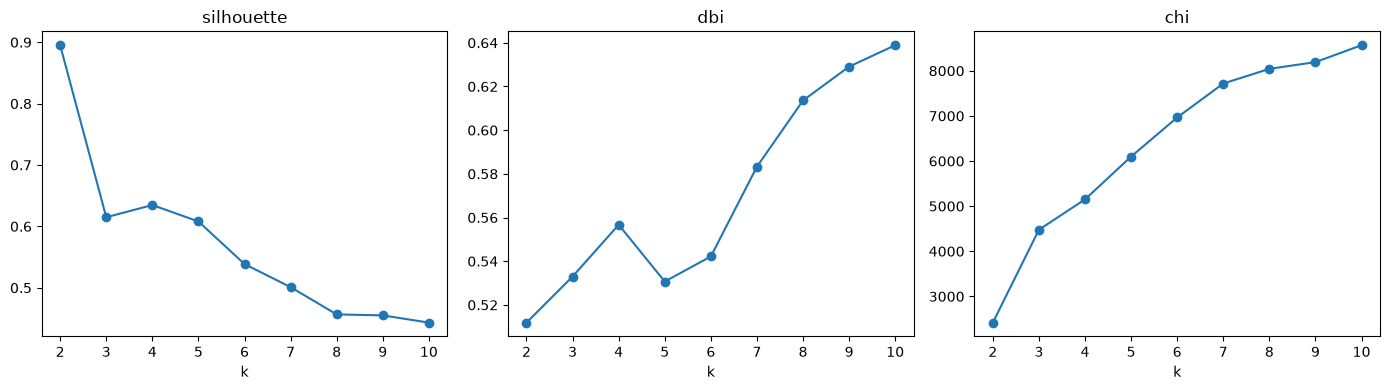

,k,silhouette,dbi,chi,inertia
0,2,0.8952,0.5119,2418.6,7205.2
1,3,0.6149,0.5330,4476.8,3658.7
2,4,0.6348,0.5567,5149.9,2456.2
3,5,0.6080,0.5307,6098.5,1690.9
4,6,0.5386,0.5422,6965.6,1240.0
5,7,0.5010,0.5833,7717.8,958.6
6,8,0.4566,0.6136,8043.0,800.4
7,9,0.4550,0.6291,8192.5,694.5
8,10,0.4432,0.6389,8567.1,595.7


In [4]:
rows = []
for k in K_GRID:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
    labels = km.labels_
    rows.append({"k": k,
                 "silhouette": round(silhouette_score(Z, labels), 4),
                 "dbi": round(davies_bouldin_score(Z, labels), 4),
                 "chi": round(calinski_harabasz_score(Z, labels), 1),
                 "inertia": round(km.inertia_, 1)})
metrics = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150)
plt.show()
metrics

**Nhận xét:** Silhouette cao nhất rơi vào k=2 (0,8952) rồi giảm mạnh ở k=3 trở đi; DBI khá bằng phẳng quanh 0,53; CHI tăng đều theo k nên không dùng để chọn k một mình.

## Chọn k và huấn luyện mô hình cuối

In [5]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

best_model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
labels = best_model.labels_
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0      24
1    4303
Name: Số khách, dtype: int64


**Nhận xét:** k=2 chia 24 khách vào 1 cụm, 4.303 khách vào cụm còn lại — lệch gần như tuyệt đối, không phải phân khúc cân đối.

## So sánh với A01-KM (Hiếu, không cố định PCA)

A01-KM cũng dùng quy tắc Silhouette lớn nhất và cho `k = 2`.

In [6]:
a01_k, a01_sil, a01_dbi, a01_chi, a01_inertia = 2, 0.8994, 0.7275, 1947.52, 8950.60
print(f"A01-KM : k={a01_k}, Silhouette={a01_sil}, DBI={a01_dbi}, CHI={a01_chi}, Inertia={a01_inertia}")
print(f"A03-KM : k={best_k}, Silhouette={metrics.loc[metrics.k==best_k,'silhouette'].iloc[0]}, "
      f"DBI={metrics.loc[metrics.k==best_k,'dbi'].iloc[0]}, "
      f"CHI={metrics.loc[metrics.k==best_k,'chi'].iloc[0]}, "
      f"Inertia={metrics.loc[metrics.k==best_k,'inertia'].iloc[0]}")

A01-KM : k=2, Silhouette=0.8994, DBI=0.7275, CHI=1947.52, Inertia=8950.6
A03-KM : k=2, Silhouette=0.8952, DBI=0.5119, CHI=2418.6, Inertia=7205.2


**Nhận xét:** A03-KM gần như trùng A01-KM: cùng chọn k=2, Silhouette 0,8952 so với 0,8994, DBI 0,5119 so với 0,7275. Ép PCA=2 (so với PCA 90% của A01) không đổi kết luận: quy tắc 'Silhouette lớn nhất' luôn chọn ra nhóm ngoại lai cực nhỏ, không phải phân khúc có ý nghĩa kinh doanh.

## Hồ sơ cụm

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,24,3.5,55.5,58396.3,0.6,23.5
1,4303,52.0,2.0,655.6,99.4,76.5


**Nhận xét:** Cụm 0 (24 khách, 0,55%) có Frequency và Monetary rất cao — đây là nhóm ngoại lai bị tách ra, không phải khách phổ thông. Cụm 1 (4.303 khách) gần với toàn bộ phần còn lại, giống hệt bức tranh ở A01-DB và A01-KM.

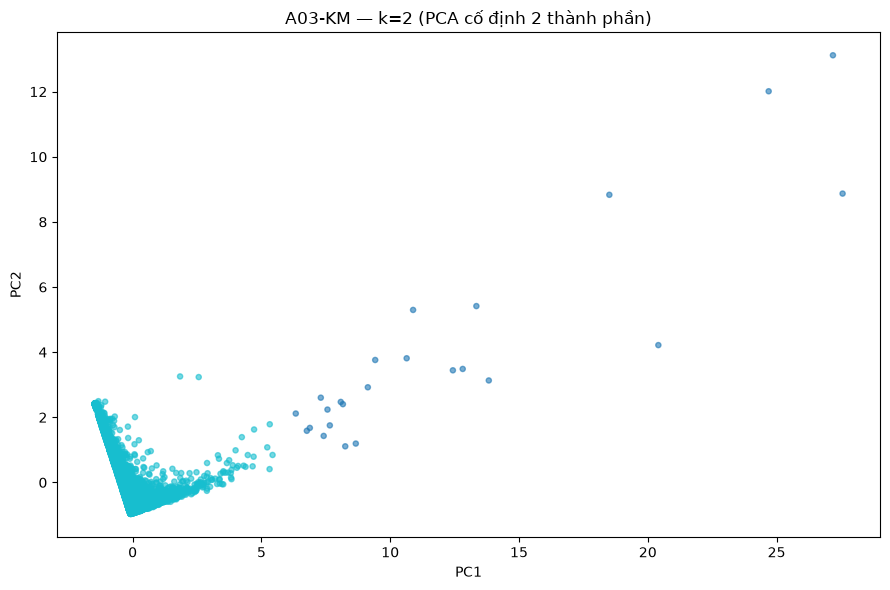

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"A03-KM — k={best_k} (PCA cố định 2 thành phần)")
plt.tight_layout()
plt.savefig(FIG / "kmeans_clusters_pca2.png", dpi=150)
plt.show()

**Nhận xét:** Hình cho thấy lại đúng mẫu đã gặp ở A01-DB: một khối khách lớn ở gốc tọa độ và vài điểm ngoại lai kéo dài theo PC1.

## k thay thế để tham khảo phân khúc

`k` theo Silhouette lớn nhất chỉ tách khách rất bất thường khỏi phần còn lại, giống A01-KM. Chạy thêm `k=4` và `k=5` (DBI/CHI tốt hơn ở vùng này) chỉ để tham khảo hồ sơ, **không thay thế lựa chọn chính thức ở trên**.

In [9]:
for k_ref in (4, 5):
    l_ref = KMeans(n_clusters=k_ref, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(Z)
    sizes = pd.Series(l_ref).value_counts().sort_index()
    print(f"k={k_ref} | Silhouette={silhouette_score(Z, l_ref):.4f} | "
          f"DBI={davies_bouldin_score(Z, l_ref):.4f} | kích thước cụm={sizes.to_dict()}")

k=4 | Silhouette=0.6348 | DBI=0.5567 | kích thước cụm={0: 3077, 1: 11, 2: 1069, 3: 170}
k=5 | Silhouette=0.6080 | DBI=0.5307 | kích thước cụm={0: 310, 1: 1058, 2: 5, 3: 20, 4: 2934}


**Nhận xét:** Ở k=4–5, DBI tốt hơn k=2 (0,53–0,56 so với 0,51 không đổi nhiều) nhưng vẫn có cụm chỉ 5–20 khách bên cạnh hai cụm lớn hàng nghìn khách. RFM thô không PCA theo tỷ trọng phương sai hợp lý không tạo ra các cụm cỡ tương đương; cần chuẩn hóa khác (log1p — nhánh B) hoặc tiêu chí chọn k khác Silhouette thuần túy.

## Lưu kết quả

In [10]:
metrics.to_csv(OUT / "kmeans_a03_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_a03_labels.csv", index=False)
params = {"experiment": "A03-KM", "features": FEATURES, "scaler": "StandardScaler",
          "pca_n_components": N_COMPONENTS, "pca_variance_kept": float(pca.explained_variance_ratio_.sum()),
          "k": best_k, "silhouette": float(metrics.loc[metrics.k==best_k, "silhouette"].iloc[0]),
          "dbi": float(metrics.loc[metrics.k==best_k, "dbi"].iloc[0]),
          "chi": float(metrics.loc[metrics.k==best_k, "chi"].iloc[0]),
          "inertia": float(metrics.loc[metrics.k==best_k, "inertia"].iloc[0])}
json.dump(params, open(OUT / "kmeans_a03_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_a03_labels.csv', 'kmeans_a03_metrics_by_k.csv', 'kmeans_a03_params.json']


**Nhận xét kết luận A03-KM:** Ép PCA về đúng 2 thành phần không thay đổi kết luận so với A01-KM — cả hai đều bị quy tắc chọn k theo Silhouette lớn nhất dẫn tới tách một nhóm ngoại lai cực nhỏ thay vì phân khúc khách hàng. Vấn đề nằm ở phân phối RFM thô lệch phải, không phải ở số chiều PCA. Cùng kết luận với A01-DB: cần thử log1p (nhánh B) hoặc tiêu chí chọn mô hình khác Silhouette đơn thuần.